In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from scikeras.wrappers import KerasRegressor
from sklearn.ensemble import RandomForestRegressor
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Input
import tensorflow.keras.backend as K
import matplotlib.pyplot as plt

Linux notebook environment warning omitted
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from pathlib import Path
import sys

def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "data_lake" / "config.json").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root")

PROJECT_ROOT = find_project_root()
PYTHON_DIR = PROJECT_ROOT / "python"
if str(PYTHON_DIR) not in sys.path:
    sys.path.insert(0, str(PYTHON_DIR))
from utils import load_config

config_file_path = PROJECT_ROOT / "data_lake" / "config.json"

config_params = load_config(config_file_path)
curated_folder = config_params.get('CURATED_FOLDER', {})
features_folder = config_params.get('FEATURES_FOLDER', {})
indicator = config_params.get('INDICATOR', {})
river_name = config_params.get('RIVER_NAME_VALUE_ENG', {})
horizon = config_params.get('HORIZON', {})
mfdfa_window = config_params.get('MFDFA_WINDOW', {})

curated_folder = PROJECT_ROOT / curated_folder
features_folder = PROJECT_ROOT / features_folder
ts_data_path = curated_folder / f'{river_name}_{indicator}_ts.csv'
mfdfa_results_path = features_folder / f'MFDFA_{river_name}_{indicator}_{mfdfa_window}_window.csv'

In [3]:
ts_data = pd.read_csv(ts_data_path)

print(ts_data)

           date  BSK5
0    2003-01-14   2.8
1    2003-01-22   2.9
2    2003-02-11   1.0
3    2003-02-24   2.2
4    2003-03-11   1.9
..          ...   ...
405  2018-10-24   2.7
406  2018-11-05   2.0
407  2018-11-22   1.8
408  2018-12-04   1.7
409  2018-12-20   2.1

[410 rows x 2 columns]


In [20]:
mfdfa_results = pd.read_csv(mfdfa_results_path)

mfdfa_results = mfdfa_results.rename(columns={mfdfa_results.columns[0]: "Index"})

print(mfdfa_results)

     Index       H  Delta_H  Delta_alpha  Alpha_0  Delta_f_alpha         B  \
0      150  0.9023   0.9945       1.2213   1.1886        -0.2160 -0.270450   
1      151  0.9153   0.8759       1.0946   1.1533        -0.3330 -0.354467   
2      152  0.8922   0.9605       1.1855   1.1810        -0.1620 -0.320624   
3      153  0.9442   1.0095       1.2365   1.2383        -0.0918 -0.246138   
4      154  0.9611   0.9147       1.1370   1.2660        -0.1710 -0.367282   
..     ...     ...      ...          ...      ...            ...       ...   
256    406  0.7681   0.9765       1.1655   1.1147         0.1620 -0.109910   
257    407  0.7845   0.7804       0.9559   1.0554         0.0270 -0.215399   
258    408  0.7761   0.9376       1.1223   1.1101         0.0288 -0.236019   
259    409  0.8113   0.9840       1.1685   1.1636         0.1170 -0.174155   
260    410  0.8484   0.7696       0.9325   1.1211         0.0450 -0.191635   

            A      beta     beta2      Mean  Volatility      Sk

In [21]:
def create_sequences(data, target, lookback):
    X, y = [], []
    for i in range(len(data) - lookback):
        X.append(data[i:i + lookback, :])
        y.append(target[i + lookback])
    return np.array(X), np.array(y)

In [22]:
early_stop = EarlyStopping(
    monitor='loss', 
    patience=10, 
    restore_best_weights=True
)

def create_lstm_model(units=32, dropout_rate=0.2, n_steps=5, n_features=5):
    model = Sequential()
    model.add(Input(shape=(n_steps, n_features)))
    model.add(LSTM(units=units, activation='tanh'))
    model.add(Dropout(dropout_rate))
    model.add(Dense(1))
    model.compile(optimizer='adam', loss='mse')
    return model

In [23]:
f_cols = ['H', 'Delta_H', 'Delta_alpha', 'Alpha_0', 'Delta_f_alpha', 'B',
     'A', 'beta', 'beta2', 'Mean', 'Volatility', 'Skew', 'Slope', 'Kurtosis', 'Entropy', 'Width']

FINAL_PREDICTION_LENGTH = horizon
R_STEP = 1
MFDFA_WINDOW = mfdfa_window

TARGET_COL = 'Future_Target'

In [24]:
target_raw_indices = (np.arange(len(mfdfa_results)) * R_STEP) + MFDFA_WINDOW + R_STEP - 1
valid_indices = target_raw_indices < len(ts_data)

final_target_indices = target_raw_indices[valid_indices]
print(final_target_indices)

[150 151 152 153 154 155 156 157 158 159 160 161 162 163 164 165 166 167
 168 169 170 171 172 173 174 175 176 177 178 179 180 181 182 183 184 185
 186 187 188 189 190 191 192 193 194 195 196 197 198 199 200 201 202 203
 204 205 206 207 208 209 210 211 212 213 214 215 216 217 218 219 220 221
 222 223 224 225 226 227 228 229 230 231 232 233 234 235 236 237 238 239
 240 241 242 243 244 245 246 247 248 249 250 251 252 253 254 255 256 257
 258 259 260 261 262 263 264 265 266 267 268 269 270 271 272 273 274 275
 276 277 278 279 280 281 282 283 284 285 286 287 288 289 290 291 292 293
 294 295 296 297 298 299 300 301 302 303 304 305 306 307 308 309 310 311
 312 313 314 315 316 317 318 319 320 321 322 323 324 325 326 327 328 329
 330 331 332 333 334 335 336 337 338 339 340 341 342 343 344 345 346 347
 348 349 350 351 352 353 354 355 356 357 358 359 360 361 362 363 364 365
 366 367 368 369 370 371 372 373 374 375 376 377 378 379 380 381 382 383
 384 385 386 387 388 389 390 391 392 393 394 395 39

In [25]:
final_features_df = mfdfa_results.iloc[final_target_indices-mfdfa_results["Index"].iloc[0]].reset_index(drop=True)
final_targets = ts_data["BSK5"].iloc[final_target_indices].values
final_features_df[TARGET_COL] = final_targets

In [26]:
print("Features array length:", len(mfdfa_results.iloc[final_target_indices-mfdfa_results["Index"][0]]))
print("Target array length:", len(ts_data["BSK5"].iloc[final_target_indices].values))

Features array length: 260
Target array length: 260


In [27]:
train_val_df = final_features_df.iloc[:-FINAL_PREDICTION_LENGTH].reset_index(drop=True)
test_df = final_features_df.iloc[-FINAL_PREDICTION_LENGTH:].reset_index(drop=True)

In [28]:
X = train_val_df[f_cols]
y = train_val_df[TARGET_COL]

# 2. Use a Tree-based model to find importance
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X, y)

# 3. Create a ranking table
feature_importance = pd.DataFrame({
    'Feature': f_cols,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(feature_importance)

          Feature  Importance
15          Width    0.189978
0               H    0.135448
14        Entropy    0.107541
10     Volatility    0.065030
3         Alpha_0    0.062075
12          Slope    0.058039
7            beta    0.052670
6               A    0.046563
5               B    0.041461
11           Skew    0.040877
8           beta2    0.038069
13       Kurtosis    0.033507
4   Delta_f_alpha    0.033395
9            Mean    0.033262
1         Delta_H    0.032572
2     Delta_alpha    0.029513


In [29]:
f_cols = feature_importance['Feature'][:6].values

print(f_cols)

['Width' 'H' 'Entropy' 'Volatility' 'Alpha_0' 'Slope']


In [30]:
results = []

for lb in [3, 4, 5]:
    print(f"\nTesting Feature Set: {f_cols} with {lb} lookback window")
    
    f_scaler = MinMaxScaler()
    t_scaler = MinMaxScaler()
        
    scaled_f = f_scaler.fit_transform(final_features_df[f_cols])
    scaled_t = t_scaler.fit_transform(final_features_df[[TARGET_COL]])
        
    X, y = [], []
    for i in range(len(scaled_f) - lb):
        X.append(scaled_f[i:i + lb, :]); y.append(scaled_t[i + lb])
    X, y = np.array(X), np.array(y)
        
    current_n_steps = X.shape[1]
    current_n_features = X.shape[2]
    
    # Define the Wrapper
    model_wrapper = KerasRegressor(
        model=create_lstm_model,
        model__n_steps=current_n_steps,
        model__n_features=current_n_features,
        epochs=200,
        verbose=0,
        callbacks=[early_stop]
    )

    # B. Define Hyperparameter Grid
    param_grid = {
        'model__units': [16, 24, 32],
        'batch_size': [8, 16, 24],
        'epochs': [100, 150]
    }

    # C. TimeSeriesSplit (The "K-Fold" for Time Series)
    # Standard K-Fold shuffles data, which ruins time series. 
    # TimeSeriesSplit keeps the temporal order.
    tscv = TimeSeriesSplit(n_splits=3) 

    grid = GridSearchCV(
        estimator=model_wrapper, 
        param_grid=param_grid, 
        cv=tscv, 
        scoring='neg_mean_squared_error',
        n_jobs=1 # Keras/Tensorflow usually works best with n_jobs=1
    )

    grid_result = grid.fit(X, y)
        
    K.clear_session()
        
    results.append({
        'feature_set': f_cols,
        'lookback': lb,
        'val_rmse': np.sqrt(abs(grid.best_score_)),
        'best_params': grid.best_params_,
        'best_estimator': grid.best_estimator_,
        'f_scaler': f_scaler, 
        't_scaler': t_scaler
    })


Testing Feature Set: ['Width' 'H' 'Entropy' 'Volatility' 'Alpha_0' 'Slope'] with 3 lookback window

Testing Feature Set: ['Width' 'H' 'Entropy' 'Volatility' 'Alpha_0' 'Slope'] with 4 lookback window

Testing Feature Set: ['Width' 'H' 'Entropy' 'Volatility' 'Alpha_0' 'Slope'] with 5 lookback window


In [31]:
champion = pd.DataFrame(results).sort_values('val_rmse').iloc[0]
best_model = champion['best_estimator']
lb = champion['lookback']
f_cols = champion['feature_set']
params = champion['best_params']

combined_df = pd.concat([train_val_df.iloc[-lb:], test_df]).reset_index(drop=True)
scaled_test_f = champion['f_scaler'].transform(combined_df[f_cols])

X_test = []
for i in range(len(scaled_test_f) - lb):
    X_test.append(scaled_test_f[i:i + lb, :])
X_test = np.array(X_test)

scaled_preds = best_model.predict(X_test)
final_preds = champion['t_scaler'].inverse_transform(scaled_preds.reshape(-1, 1))
actuals = test_df[TARGET_COL].values

# Final Metric
test_rmse = np.sqrt(mean_squared_error(actuals, final_preds))
print(f"--- CHAMPION MODEL ---")
print(f"Features: {f_cols} | Lookback: {lb}")
print(f"Params: {params}")
print(f"Final Test RMSE (on {horizon} points): {test_rmse:.4f}")

--- CHAMPION MODEL ---
Features: ['Width' 'H' 'Entropy' 'Volatility' 'Alpha_0' 'Slope'] | Lookback: 5
Params: {'batch_size': 16, 'epochs': 100, 'model__units': 24}
Final Test RMSE (on 10 points): 1.2786


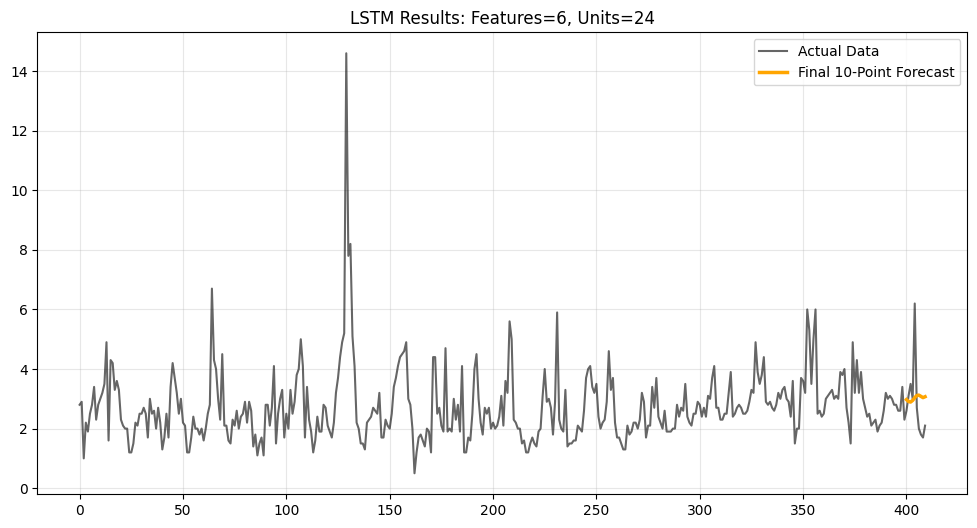

In [32]:
plt.figure(figsize=(12, 6))
plt.plot(ts_data["BSK5"].values, color='black', alpha=0.6, label='Actual Data')
# Highlight the final 10
plt.plot(range(len(ts_data["BSK5"].values)-horizon, len(ts_data["BSK5"].values)), final_preds.flatten(), 
         color='orange', linewidth=2.5, label='Final 10-Point Forecast')

plt.title(f"LSTM Results: Features={len(f_cols)}, Units={champion['best_params']['model__units']}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
--- CHAMPION MODEL ---
Features: ['Width' 'H' 'Entropy' 'beta' 'Volatility' 'Alpha_0'] | Lookback: 3
Params: {'batch_size': 24, 'epochs': 100, 'model__units': 16}
Final Test RMSE (on 10 points): 1.1808